# Assignment 2: Data Processing

**Name:** Tse Yan Wing Alvina  
**Team Members (if any):** [Add names here]

---

## Instructions
1. **Save your work:** In Colab, use **File → Save a copy in Drive**, or download the notebook to your local machine.
2. **Run in order:** Run cells from top to bottom because execution order matters.
3. **Complete the student areas:** Follow the comments in each section.
4. **Required experiments:** Visual Feature Analysis, Scaling Exploration
5. **Required metrics:** At the end, create a summary documenting feature insights derived from the data

---

***Attribution**: This notebook was created by Michael Roman for use in the CYBERSEC 520 course at Duke University. It was adapted from lecture notes. Gemini 3 Pro was used to format and clean up this notebook.*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mproman/CYBERSEC520/blob/main/content/assignments/Assignment_1.ipynb)

## Step 0: Notebook Setup
We need to bring in our tools. These are the standard libraries used by Data Scientists everywhere.
* **Pandas:** For handling data like Excel sheets.
* **Seaborn/Matplotlib:** For drawing graphs.
* **Sklearn:** The Machine Learning library.

**Action:** Click the "Play" button on the cell below.

In [ ]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Import machine-learning tools
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn import datasets
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

# Make the graphs look nice
plt.style.use("seaborn-v0_8-whitegrid")
print("Setup complete! You are ready to start.")

Setup complete! You are ready to start.


## Step 1: Data Loading and Preprocessing

**Steps:**
1. Download `Monday-WorkingHours.pcap_ISCX.csv` and one attack-day CSV from the [Canvas Datasets folder](https://canvas.duke.edu/courses/82545/files/folder/Datasets).
2. Combine the Monday file with the attack-day file. **Do not use Monday by itself:** it contains only benign traffic.
3. Create a binary target with two classes: `BENIGN` and `ATTACK`.
4. Clean missing, infinite, and invalid values before modeling.
5. Subsample the data to reduce runtime.
6. Update both path variables in the loading cell below.

> **Sampling hint:** A simple random sample may omit rare attacks. Consider sampling from `BENIGN` and `ATTACK` separately. When splitting the sample, use a fixed random seed and `stratify=y` so both classes appear in the training and test sets.

The Google Drive cell is optional and is needed only when your files are stored in Drive while using Colab.

In [ ]:
# Optional: mount Google Drive when running this notebook in Colab.
# Skip this cell if you uploaded files directly, use Kaggle, or run locally.
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("Google Drive mounting is only needed in Colab.")

Mounted at /content/drive


In [ ]:
# Set the paths to the Wednesday CSV file
path = "/content/drive/MyDrive/CYBERSEC520/Datasets/Wednesday-workingHours.pcap_ISCX.csv"

df = pd.read_csv(path)

print(f"Combined size: {len(df):,} rows")
print(df.head(5))

Combined size: 249,097 rows
    Destination Port   Flow Duration   Total Fwd Packets  \
0                 80           38308                   1   
1                389             479                  11   
2                 88            1095                  10   
3                389           15206                  17   
4                 88            1092                   9   

    Total Backward Packets  Total Length of Fwd Packets  \
0                        1                            6   
1                        5                          172   
2                        6                         3150   
3                       12                         3452   
4                        6                         3150   

    Total Length of Bwd Packets   Fwd Packet Length Max  \
0                             6                       6   
1                           326                      79   
2                          3150                    1575   
3                   

### 1.1 Clean, Label, and Subsample
Cybersecurity datasets are large and often contain missing or infinite values.

In the next cell:

1. Normalize the column names.
2. Remove invalid values.
3. Keep only BENIGN and DoS Slowloris datapoints
4. Print the class counts and verify that both classes are present.

**Hint:** Sample from each class separately instead of taking one unrestricted random sample. The comments provide guidance, but you must complete the implementation.

In [ ]:
# Complete each step below.

# 1. Normalize column names so " Label" and "Label" are handled consistently.
df.columns = df.columns.str.strip()

# 2. Replace positive/negative infinity with NaN, then remove invalid rows.
df.replace([-np.inf, np.inf], np.nan, inplace = True)
df = df.dropna()
#3. Drop other DoS attacks, focus on Slowloris
df = df.drop(df[(df['Label'] == 'DoS Hulk') | (df['Label'] == 'DoS Slowhttptest')].index)

df['Label'].value_counts()
print(df.head(5))

   Destination Port  Flow Duration  Total Fwd Packets  Total Backward Packets  \
0                80          38308                  1                       1   
1               389            479                 11                       5   
2                88           1095                 10                       6   
3               389          15206                 17                      12   
4                88           1092                  9                       6   

   Total Length of Fwd Packets  Total Length of Bwd Packets  \
0                            6                            6   
1                          172                          326   
2                         3150                         3150   
3                         3452                         6660   
4                         3150                         3152   

   Fwd Packet Length Max  Fwd Packet Length Min  Fwd Packet Length Mean  \
0                      6                      6            

### 1.2 Prepare the Data (Port Encoding / Train-Test Split)
Separate the **features** from the binary **target**, and then create training and test sets.

Use `BinaryLabel` as the target. Do not include either the original `Label` column or `BinaryLabel` among the model features.

Convert Port Numbers to Port frequency, and create a stratified train-test split of 70/30.

In [ ]:

#1. Convert Port Numbers to Port Frequency.
port_frequency = df['Destination Port'].value_counts().to_dict()
df['Destination Port Frequency'] = df['Destination Port'].map(port_frequency)
df.drop(['Destination Port'], axis = 1, inplace = True)

y = df['Label']
X = df.drop(columns = ['Label'])

#2. Create one fixed stratified train/test split.
X_train, X_test, y_train, y_test = train_test_split(
     X,
     y,
     test_size=0.3,
     random_state=42,
     stratify=y,
 )

print(df.head(5))


   Flow Duration  Total Fwd Packets  Total Backward Packets  \
0          38308                  1                       1   
1            479                 11                       5   
2           1095                 10                       6   
3          15206                 17                      12   
4           1092                  9                       6   

   Total Length of Fwd Packets  Total Length of Bwd Packets  \
0                            6                            6   
1                          172                          326   
2                         3150                         3150   
3                         3452                         6660   
4                         3150                         3152   

   Fwd Packet Length Max  Fwd Packet Length Min  Fwd Packet Length Mean  \
0                      6                      6                6.000000   
1                     79                      0               15.636364   
2                

## Step 2: Visual Feature Analysis

A. Box Plots/Pairplots/Histograms

Create visualization for 6 important features, and use all three visualization types.
Compare the attack vs benign distributions
Hypothesis: Why would this attack show these patterns? Write 1-2 sentences per feature.


B. Dimensionality Reduction Visualization

Apply ONE method: PCA, t-SNE, or UMAP. Create a 2D scatter plot colored by class.
Evaluate cluster separability and overlapping regions.
Interpret whether this aligns with expected attack signatures.

###**A.0 Forward IAT Mean, Total Fwd Packets, Total Length of Fwd Packets, Total Length of Bwd Packets -- Big Picture**  

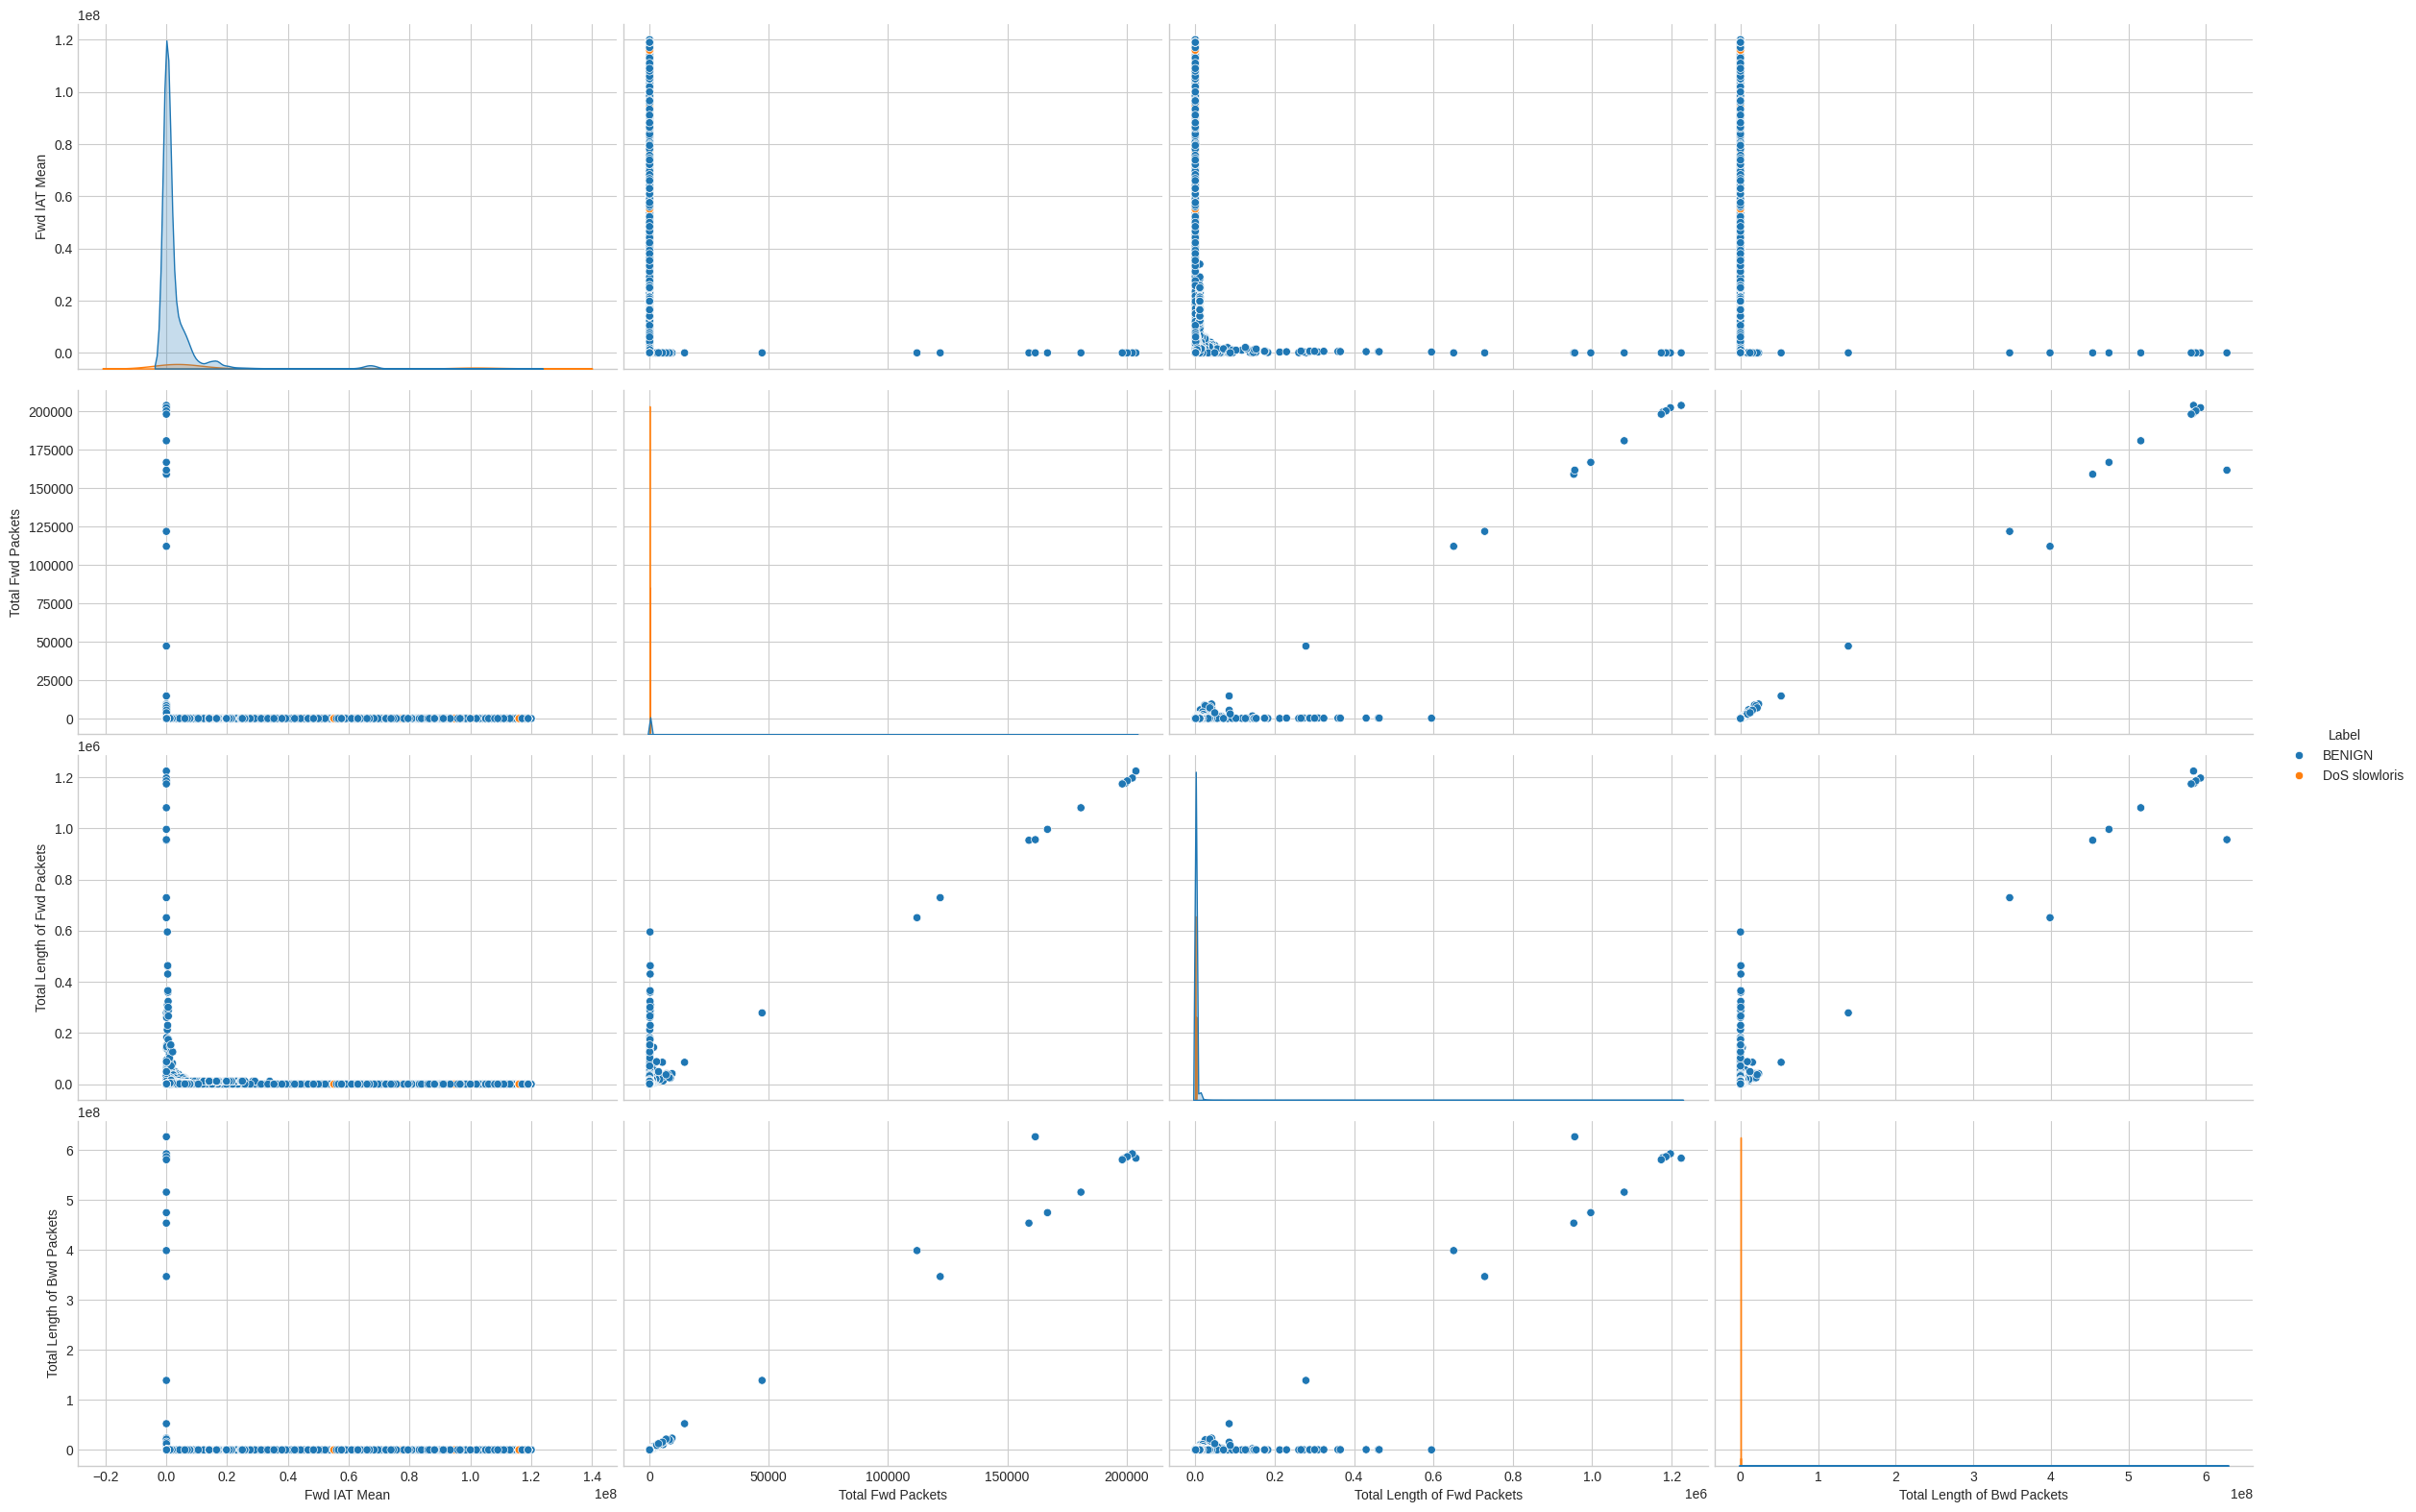

In [ ]:
data = df[['Fwd IAT Mean', 'Total Fwd Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Label']]
sns.pairplot(data, hue = 'Label', height = 4, aspect = 1.5)

The data that is most interesting here are the ones on the diagonal. We can see that:
1. The Forward IAT Mean is more skewed towards the left for BENIGN data when compared to Slowloris data, which would make sense as the time between packets in a Slowloris attack is kept longer so to keep the connection open.
2. The Total Fwd Packets, Total Length of Fwd Packets, and Total Length of Backward Packets in a Slowloris attack connection is much lower than that of benign traffic in general, and do not show as much variation as benign traffic, which has varying lengths/number of packets and seems more random.  


For the off-diagonal data, there isn't much to see. It would make sense that the total fwd packets would be positively correlated with the total bwd packets and total length of fws packets in a benign setting, and we do not see much different between the benign and Slowloris settings (at least, in the plots we see here). We can look more into it in later experiments.

### **A.1 Forward IAT Mean**

<Axes: xlabel='Fwd IAT Mean', ylabel='Count'>

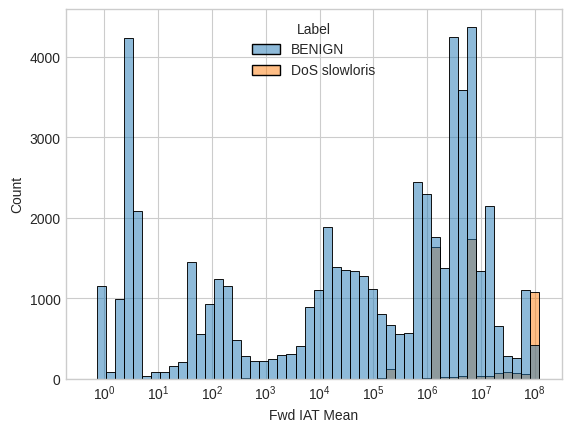

In [ ]:
sns.histplot(
    data = df,
    x = 'Fwd IAT Mean',
    hue = 'Label',
    bins = 50,
    log_scale = True
)

As expected, the Fwd IAT Mean for Slowloris data skews towards the right. This tracks with the way the Slowloris attack is conducted.

### **A.2 Feature 2: Flow duration**

<Axes: xlabel='Label', ylabel='Flow Duration'>

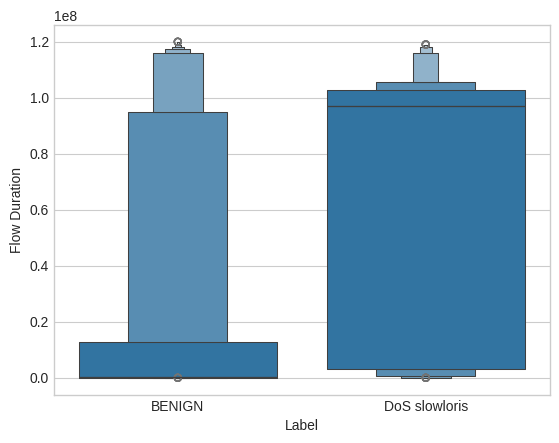

In [ ]:
sns.boxenplot(data = df, x = 'Label', y = 'Flow Duration')

We can see that in general, the Flow Duration for BENIGN traffic is skewed towards the lower end with most of the data below 0.2 (flow duration is lower) while most of the DOS Slowloris datapoints are concentrated between around 0.1 to 1, with a longer flow duration in general. It would make sense as the incomplete HTTP packets sent during a connection are deliberately spaced apart so to keep the connection open as long as possible (that is the basis of the attack) so the first and last packet in a connection would be more spaced apart compared to normal traffic.

### **A.3 Feature 3: Total Fwd Packets**

<Axes: xlabel='Total Fwd Packets', ylabel='Count'>

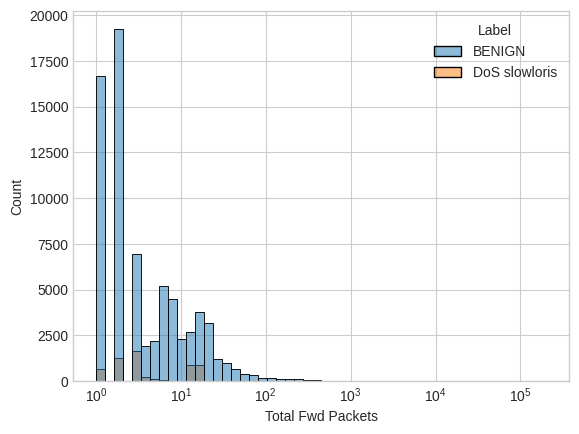

In [ ]:
sns.histplot(
    data = df,
    x = 'Total Fwd Packets',
    hue = 'Label',
    bins = 50,
    log_scale = True
)

As mentioned in Experiment A.1, as shown in this plot, the Dos Slowloris attack show less variation in the number of packets when compared to benign traffic. However, there are some cases when the total forward packets during a Slowloris attack is similar to that to benign traffic in a connection. We thought that the total forward packets would be lower as they would be sent more minimally to prevent detection. Upon reflection, that might not be the case as it would make more sense to try and mimic the frequency of normal network traffic. Hence, this might not be the best indicator of Slowloris traffic.

### **A.4 Feature 4: Total Length of Fwd Packets**

<Axes: xlabel='Total Length of Fwd Packets', ylabel='Count'>

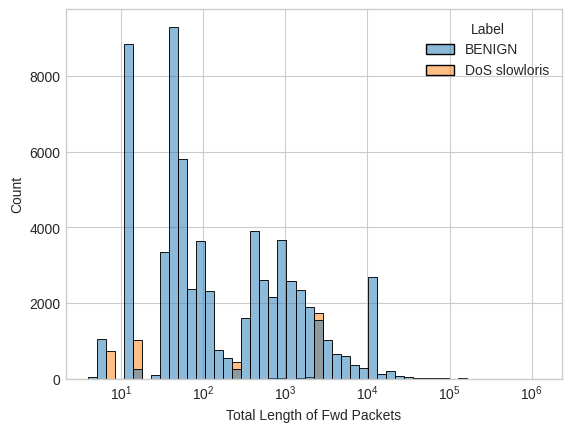

In [ ]:
sns.histplot(
    data = df,
    x = 'Total Length of Fwd Packets',
    hue = 'Label',
    bins = 50,
    log_scale = True
)

As mentioned in Experiment A.1, as shown in this plot, the Dos Slowloris attack show less variation in length when compared to benign traffic. I expected the length of Slowloris forward packets to be shorter than benign traffic as the HTTP headers are incomplete, but there are instances when the packet length is similar to that as benign traffic. Hence, I don't think forward packet length is a good indicator in classifying whether traffic is benign or malicious (when considering length alone).

### **A.5 Feature 5: Total Length of Backward Packets**

<Axes: xlabel='Total Length of Bwd Packets', ylabel='Count'>

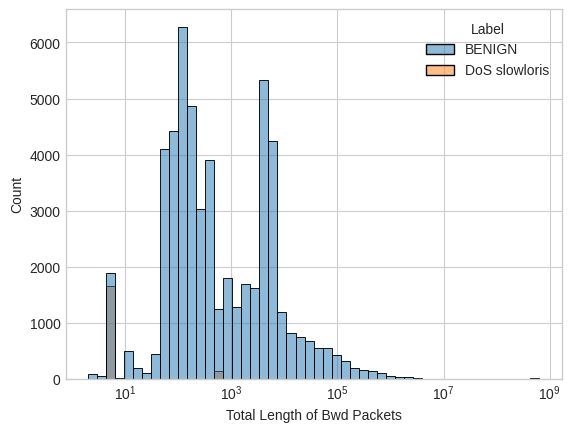

In [ ]:
sns.histplot(
    data = df,
    x = 'Total Length of Bwd Packets',
    hue = 'Label',
    bins = 50,
    log_scale = True
)

I wanted to make the data clearer from Experiment 1. From this plot we can see that in a Slowloris attack, the total length of Bwd Packets is skewed to the left (shorter in general, with small outliers at 10^3). This is because the backward packets only contain acknowledgement messages, and do not contain any content, unlike normal traffic.

### **A.6 FIN Flag Count**

<Axes: xlabel='FIN Flag Count', ylabel='Count'>

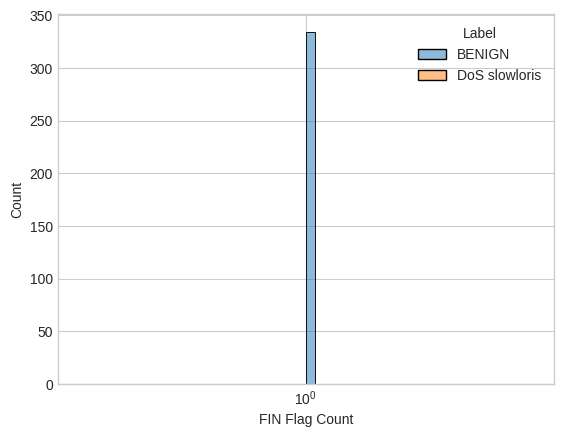

In [ ]:
sns.histplot(
    data = df,
    x = 'FIN Flag Count',
    hue = 'Label',
    bins = 50,
    log_scale = True
)

As the connection is not terminated (HTTP request is not completed) during a Slowloris attack, no FIN flags are sent during the attack (as shown from the data) while in benign traffic, a FIN flag is sent when the connection ends (when the HTTP request is completed).

### **A.7 Extra: just testing if Idle Mean would be a better indicator than some of these**

<Axes: xlabel='Idle Mean', ylabel='Count'>

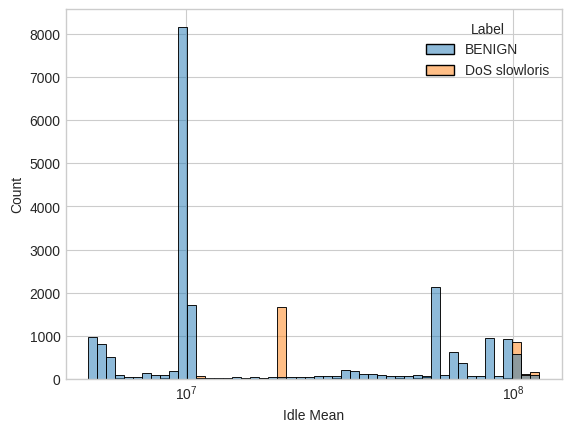

In [ ]:
sns.histplot(
    data = df,
    x = 'Idle Mean',
    hue = 'Label',
    bins = 50,
    log_scale = True
)

The Idle Mean of a Slowloris attack is generally longer than that of benign traffic. The packets are sent slowly and sporadically and there are long gaps between packets sent where nothing happens.

### **B.1 Applying PCA**

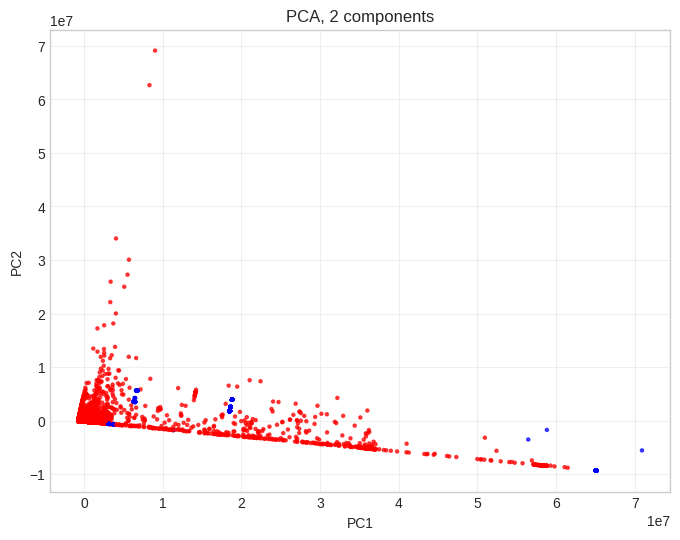

In [ ]:
pca = PCA(n_components = 2)
rob_scaler = RobustScaler()
X_scaled = rob_scaler.fit_transform(X)
X_pca = pca.fit_transform(X_scaled)

color = {
    'BENIGN' : 'red',
    'DoS slowloris' : 'blue'
}

colors = [color[i] for i in y]

plt.figure(figsize = (8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c = colors, s=5, alpha=0.7)
plt.title('PCA, 2 components')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.grid(True, alpha = 0.3)
plt.show()



We can see that there is some overlap between the two clusters (BENIGN in red, Dos Slowloris in blue), but there are also some outliers towards the right edge of the graph. This makes sense as DoS Slowloris has some features that differ from benign attacks (as we established before, such as Flow Duration, IAT Mean, FIN Flag Count etc), but also as some features are almost indistinguishable from benign traffic (due to the nature of the attack, and also because generally attackers want to blend into benign traffic), it would make sense that there would be some data overlap.

### **Extra (out of interest): what if i use umap instead?**

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP(min_dist=0.05, n_jobs=1, n_neighbors=20, random_state=42, verbose=True)
Tue Sep 29 18:45:30 2026 Construct fuzzy simplicial set
Tue Sep 29 18:45:30 2026 Finding Nearest Neighbors
Tue Sep 29 18:45:30 2026 Building RP forest with 19 trees
Tue Sep 29 18:45:38 2026 NN descent for 16 iterations
	 1  /  16
	 2  /  16
	Stopping threshold met -- exiting after 2 iterations
Tue Sep 29 18:46:00 2026 Finished Nearest Neighbor Search
Tue Sep 29 18:46:07 2026 Construct embedding


/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


Epochs completed:   0%|            0/200 [00:00]

	completed  0  /  200 epochs
	completed  20  /  200 epochs
	completed  40  /  200 epochs
	completed  60  /  200 epochs
	completed  80  /  200 epochs
	completed  100  /  200 epochs
	completed  120  /  200 epochs
	completed  140  /  200 epochs
	completed  160  /  200 epochs
	completed  180  /  200 epochs
Tue Sep 29 18:55:45 2026 Finished embedding


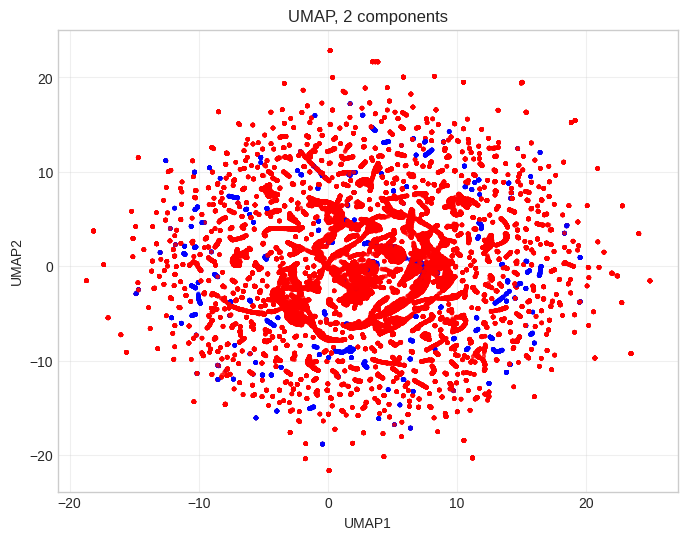

In [ ]:
umap_reducer = umap.UMAP(
    n_components=2,
    n_neighbors=20,       # Controls local vs global structure (5-50 typical)
    min_dist=0.05,         # Controls clustering tightness (0.0-0.99)
    metric='euclidean',
    random_state=42,
    verbose=True
)
X_umap = umap_reducer.fit_transform(X_scaled)

plt.figure(figsize = (8, 6))
plt.scatter(X_umap[:, 0], X_umap[:, 1], c = colors, s=5, alpha=0.7)
plt.title('UMAP, 2 components')
plt.xlabel('UMAP1')
plt.ylabel('UMAP2')
plt.grid(True, alpha = 0.3)
plt.show()




To understand the data better I also tried UMAP to see what results it would give me. We can see that for the BENIGN data, it is more clustered in the center of the 2D map, while DoS Slowloris data is more evenly spread out/slightly more clustered towards the edges. There is overlap between benign and attack data, but it would make sense for the reasons stated above, and we can see that the attack data form a different pattern/do not form a general trend as the benign data and are more clustered at the "outlier" part of the benign data (away from the center). This overlap might also be because we are reducing many dimensions to two dimensions.

## Step 3: Scaling Exploration
Important: Fit scalers only on **BENIGN** training data (attack traffic is out-of-distribution!)

Apply appropriate scaling methods and compare:


**StandardScaler** - Assumes symmetric/normal distribution

**RobustScaler** - Handles outliers and skewed distributions using median/IQR


Analysis (Answered in part 4):

Visualize scaled distributions for your top 5 features using histograms or box plots

Identify skewness: Which features are heavily skewed? Does RobustScaler preserve better separation?

Document: For symmetric vs skewed features, which scaler works best?

Critical thinking: Why should we fit only on benign data in production IDS scenarios? (Answer inline)

0       -0.014985
1       -0.014939
2       -0.014528
3       -0.014018
4       -0.014528
           ...   
78694   -0.014880
78695   -0.014971
78696   -0.014974
78697   -0.014986
78698   -0.014930
Name: Total Length of Bwd Packets, Length: 78699, dtype: float64
0       -0.070627
1        0.104572
2        1.650698
3        3.572406
4        1.651793
           ...   
78694    0.325760
78695   -0.015330
78696   -0.030112
78697   -0.073912
78698    0.139064
Name: Total Length of Bwd Packets, Length: 78699, dtype: float64


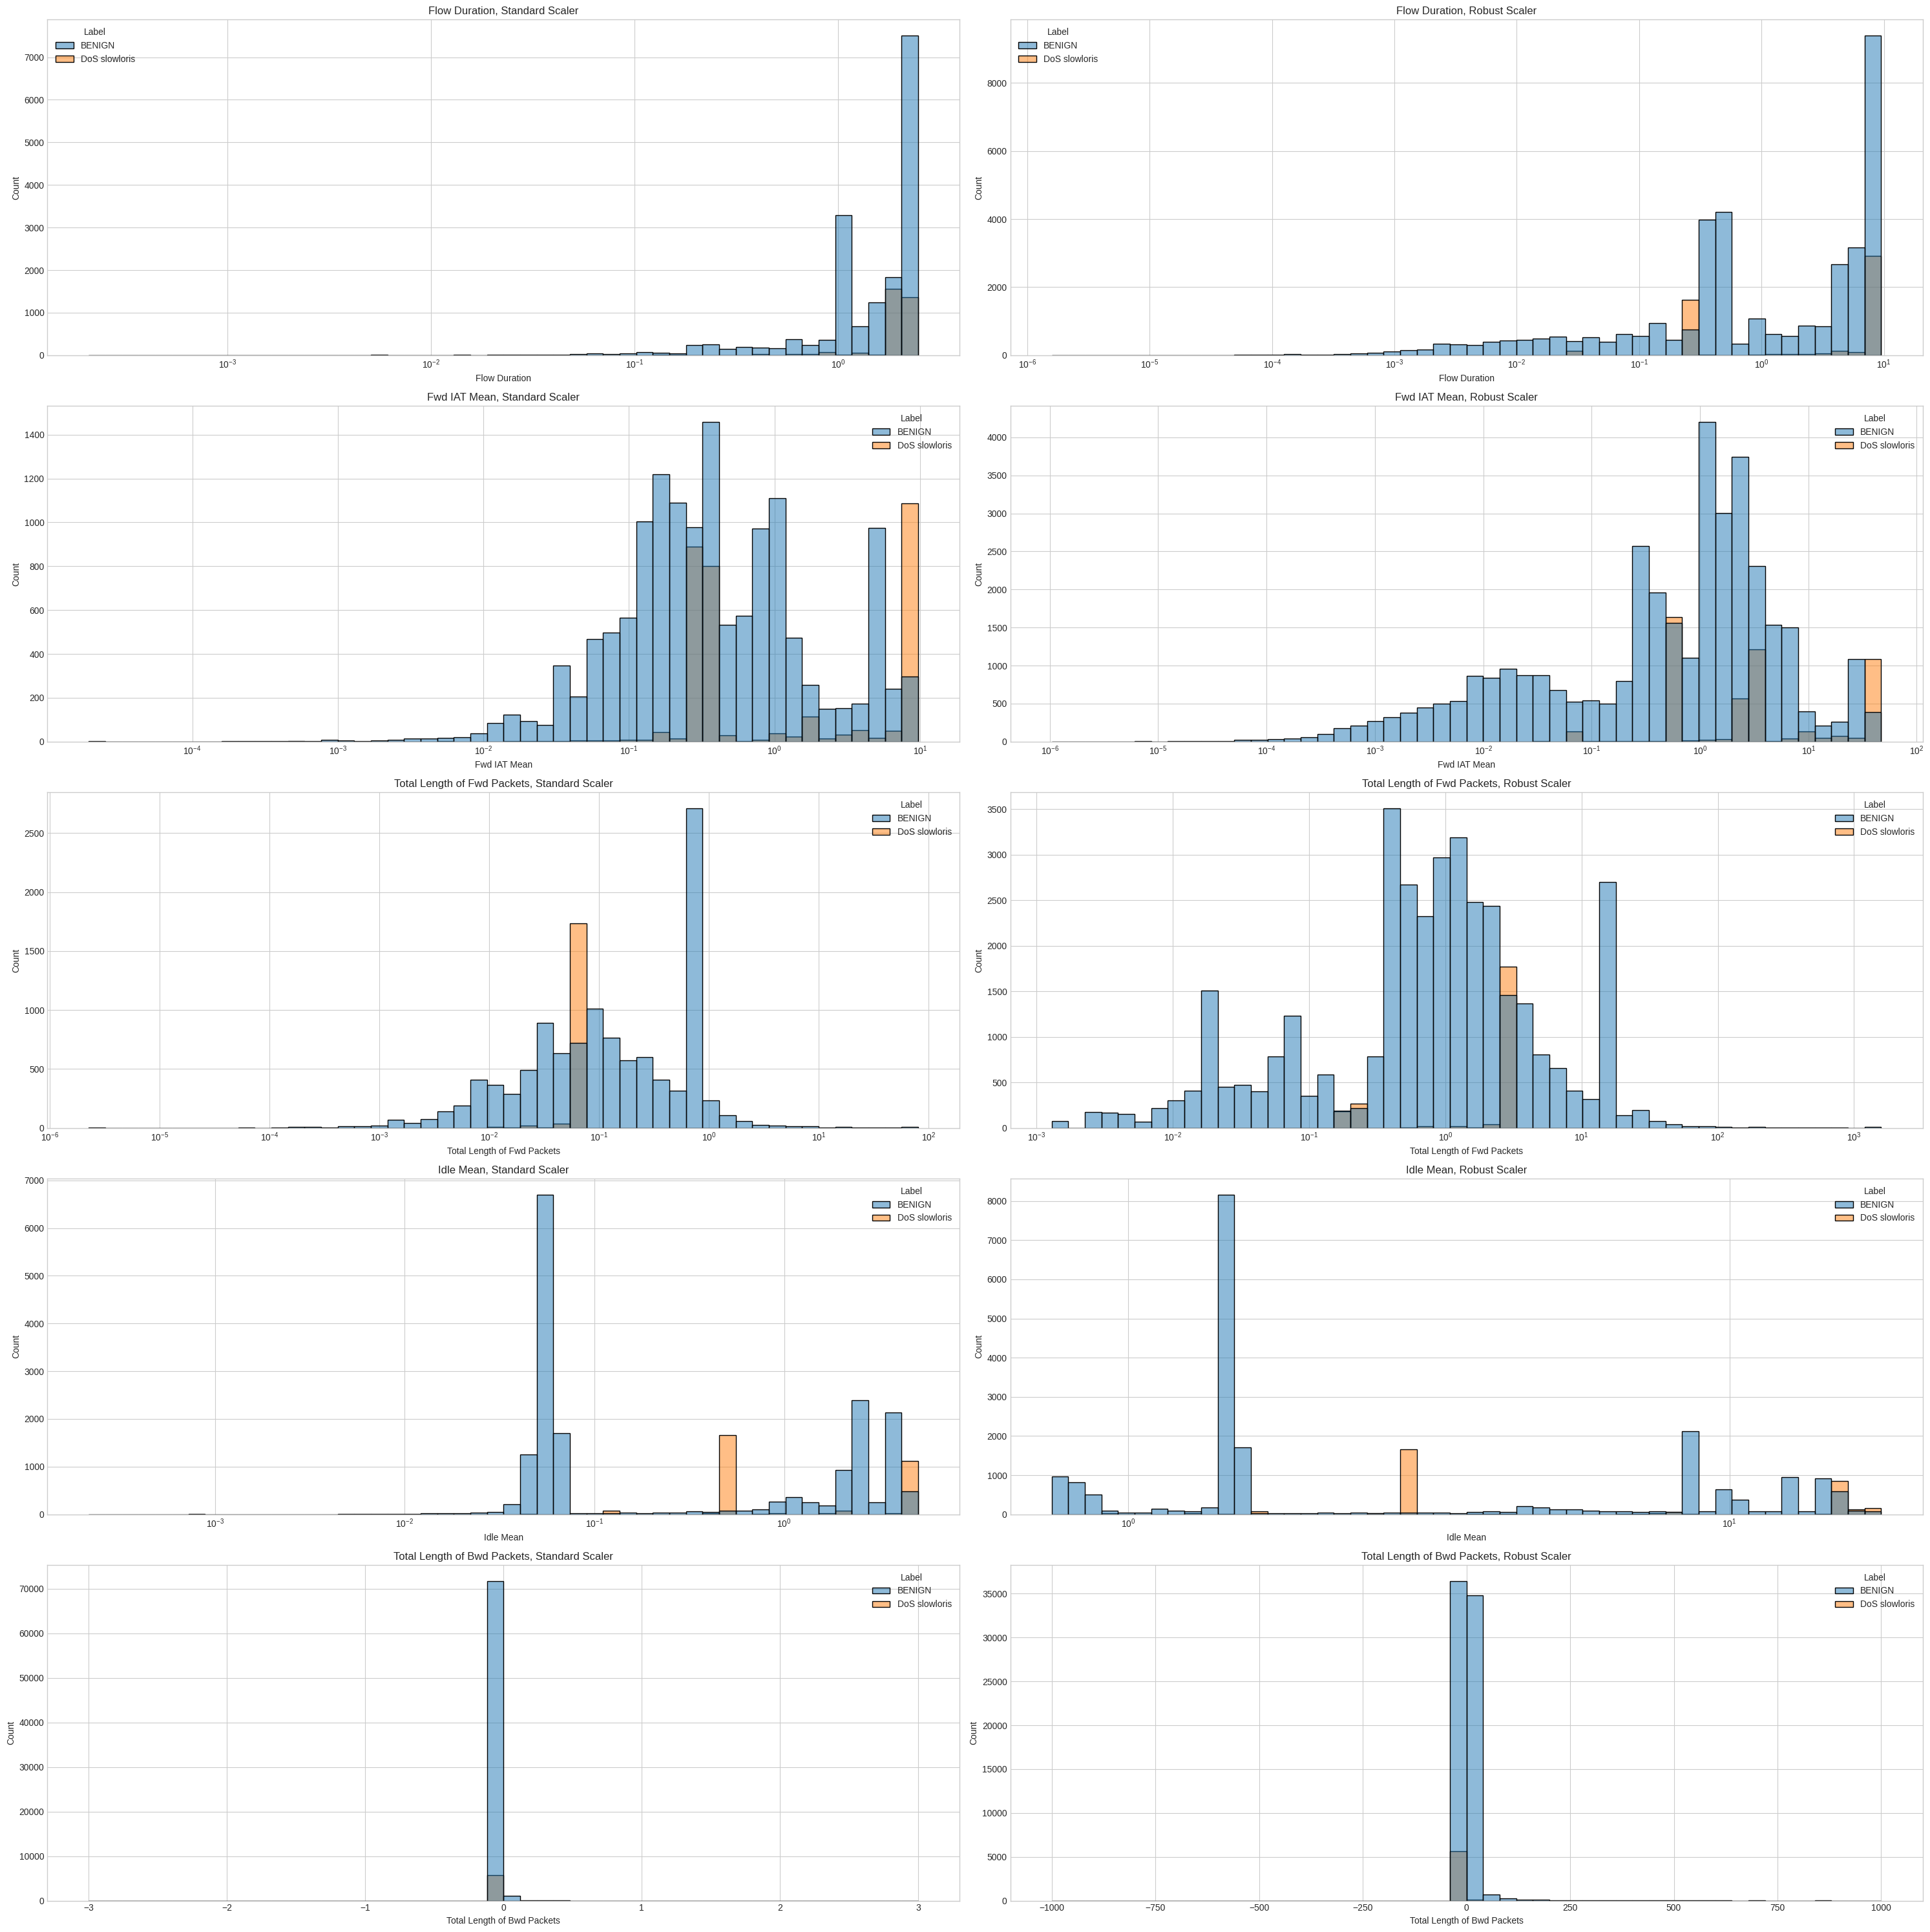

In [ ]:
df_benign = df.drop(df[(df['Label'] == 'DoS slowloris')].index)
X_benign = df_benign.drop(columns = ['Label'])

std_scaler = StandardScaler()
robust_scaler = RobustScaler()
X_scaled_std = std_scaler.fit_transform(X_benign)
X_scaled_robust = robust_scaler.fit_transform(X_benign)

X_dropped = df.drop(columns = ['Label'])
X_std = pd.DataFrame(std_scaler.transform(X_dropped), columns = X_dropped.columns)
X_robust = pd.DataFrame(robust_scaler.transform(X_dropped), columns = X_dropped.columns)

X_std['Label'] = df['Label'].values
X_robust['Label'] = df['Label'].values


features = ['Flow Duration', 'Fwd IAT Mean', 'Total Length of Fwd Packets','Idle Mean','Total Length of Bwd Packets']

print(X_std['Total Length of Bwd Packets'])
print(X_robust['Total Length of Bwd Packets'])

fig, axes = plt.subplots(5, 2, figsize=(30, 30))
temp = 0
for i in features[0:4]:

  sns.histplot(
    data = X_std,
    x = i,
    hue = 'Label',
    bins = 50,
    ax = axes[temp, 0],
    log_scale = True,
)
  axes[temp, 0].set_title(f"{i}, Standard Scaler")


  sns.histplot(
    data = X_robust,
    x = i,
    hue = 'Label',
    bins = 50,
    ax = axes[temp, 1],
    log_scale = True,
)
  axes[temp, 1].set_title(f"{i}, Robust Scaler")
  temp += 1

sns.histplot(
    data = X_std,
    x = 'Total Length of Bwd Packets',
    hue = 'Label',
    bins = 50,
    binrange = (-3, 3),
    ax = axes[4, 0],
)
axes[4, 0].set_title("Total Length of Bwd Packets, Standard Scaler")


sns.histplot(
    data = X_robust,
    x = 'Total Length of Bwd Packets',
    hue = 'Label',
    bins = 50,
    binrange = (-1000, 1000),
    ax = axes[4, 1],
)
axes[4, 1].set_title("Total Length of Bwd Packets, Robust Scaler")


plt.tight_layout()
plt.show()





## Step 4: Documentation and Reflection

### Experiment summary

| Feature Name | Most Discriminative? | Skewed Distribution? | Best Scaler | Cybersecurity Explanation|
|---|---|---:|---:|---:|
| Flow Duration| Yes | Yes| Robust| Explained in 5.1 |
| Forward IAT Mean | Yes | Yes| Robust| Explained in 5.1|
| Total length of Fwd packets | No | No| Standard| Explained in 5.2|
| Total length of Bwd packets | Yes| Yes| Robust | Explained in 5.1 |
| Idle Mean | Somewhat| Yes| Robust| Explained in 5.1|

For skewed features, Robust Scaler works better as it is less sensitive to outliers (it takes IQR into consideration). From the data above, it brings more clarity and gives more insight into the general shape of the data.


### Step 5: Reflection & Critical Thinking

Write no more than 1-page reflection addressing:

1. Top 3 Discriminative Features: Rank them with cybersecurity justification
2. Surprises: Did any feature behave contrary to your intuition? Why might this occur?
3. Attack Alignment: Does visual analysis match known characteristics of your chosen attack?
4. Scaling Impact: Which scaler handled skewness best for your dataset?
5. Detection Feasibility: Based on EDA alone, how difficult would classifier design be? What challenges exist?
6. Production Considerations: Why is benign-only scaler fitting critical for real-world IDS?

1. The 3 most discriminative features are Flow Duration > Forward IAT Mean = Idle Mean. For Flow Duration, the DoS data is significantly more right-skewed than normal data as packets are deliberately sent slowly to keep the connection open as long as possible (that is the basis of the attack). Forward IAT Mean and Idle Mean are also good indicators as they show right-skew: for forward IAT mean, as explained above, packets are sent far apart from each other to keep the connection open as long as possible, and for idle mean, similarly, the waiting time between packets is long for the same reason. Although Total Length of Bwd Packets shows left skew for attack data (as the packets returned only contains acknowledgement and no data), there is a lot of overlap between benign and attack data , which may make it harder to classify.

2. Yes. I expected the total length of forward packets to be shorter than that of benign traffic due to incomplete HTTP headers, but the data does not seem to indicate that. In general, I think I expected the DoS Slowloris data to show a greater difference compared to benign data, but the data is more similar than I thought it would be (though in the more discriminative cases we can see that the attack data is more skewed/leans towards a specific side). This would make sense as attackers would try to mimic benign data so to blend into benign traffic.

3. In general, from the analysis above, we can see that the data given does give good indicators towards whether the data is malicious. The PCA and UMAP analysis also give information (if we know prior what data is benign and what is malicious), but the clusters are hard to tell apart if it is not known, as there is quite a bit of overlap.

4. I think Robust Scaler worked better for my skewed distributions, which can especially be seen in 'Total Length of Bwd Packets'. It allows for better clarity when outliers are present. As the Standard Staler is N(0,1), if outliers are present, it compresses the (non-outlier) data and it can be hard to visualize, while Robust Scaler scales by IQR and median, and is better above to scale skewed data so that it isn't as compressed.

5. You would have to consider the relationships between many different variables in this case (as we can see, PCA and UMAP do not separate benign and malicious data well). Without domain knowledge it might be hard to choose which features to look out for, or how to handle/interpret outliers.

6. If we fit the trainer on attack data along with benign data, the model learns the patterns of the attack data as well. What we want is for the model to distinguish between benign and attack data, and giving the model the attack data skews the scaling. Often attack data shows more skewing/outliers than benign data, and scaling by benign data can better show the outliers during testing, which makes it more sensitive to abnormal datapoints.